In [1]:
%pip -q install datasets pandas matplotlib pyarrow sentence-transformers faiss-cpu requests

In [2]:
import re
import json
import time
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import defaultdict
from datasets import load_dataset
from sentence_transformers import SentenceTransformer
import faiss

SEED = 42
np.random.seed(SEED)

print("All imports successful!")

All imports successful!


In [3]:
DATASET_ID = "allenai/qasper"

response = requests.get(
    "https://datasets-server.huggingface.co/parquet",
    params={"dataset": DATASET_ID},
    timeout=60,
)

response.raise_for_status()
parquet_info = response.json()

print("Available splits and files:")

for item in parquet_info["parquet_files"]:
    print(
        item["config"],
        item["split"],
        item["url"],
    )

Available splits and files:
qasper test https://huggingface.co/datasets/allenai/qasper/resolve/refs%2Fconvert%2Fparquet/qasper/test/0000.parquet
qasper train https://huggingface.co/datasets/allenai/qasper/resolve/refs%2Fconvert%2Fparquet/qasper/train/0000.parquet
qasper validation https://huggingface.co/datasets/allenai/qasper/resolve/refs%2Fconvert%2Fparquet/qasper/validation/0000.parquet


In [4]:
parquet_files = parquet_info["parquet_files"]

# Find the config containing the standard QASPER splits.
configs = list(dict.fromkeys(
    item["config"] for item in parquet_files
))

print("Available configs:", configs)

preferred_config = (
    "qasper" if "qasper" in configs else configs[0]
)

data_files = {}

for split_name in ["train", "validation", "test"]:
    urls = [
        item["url"]
        for item in parquet_files
        if item["config"] == preferred_config
        and item["split"] == split_name
    ]

    if urls:
        data_files[split_name] = urls

if not data_files:
    raise ValueError(
        "No usable Parquet splits found. Inspect parquet_info above."
    )

dataset = load_dataset(
    "parquet",
    data_files=data_files,
)

print(dataset)

Available configs: ['qasper']


qasper/train/0000.parquet: reconstructing file:   0%|          |  0.00B / 14.4MB            

qasper/train/0000.parquet: downloading bytes:           |  0.00B            

qasper/validation/0000.parquet: reconstructing file:   0%|          |  0.00B / 4.75MB            

qasper/validation/0000.parquet: downloading bytes:           |  0.00B            

...

qasper/test/0000.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'title', 'abstract', 'full_text', 'qas', 'figures_and_tables'],
        num_rows: 888
    })
    validation: Dataset({
        features: ['id', 'title', 'abstract', 'full_text', 'qas', 'figures_and_tables'],
        num_rows: 281
    })
    test: Dataset({
        features: ['id', 'title', 'abstract', 'full_text', 'qas', 'figures_and_tables'],
        num_rows: 416
    })
})


In [5]:
EVAL_SPLIT = "validation"

# Increase to None when you want to evaluate the entire split.
MAX_PAPERS = 30
MAX_QUESTIONS_PER_PAPER = 10

TOP_K = 5

CHUNK_SIZE = 200
CHUNK_OVERLAP = 40

MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"

print("Split:", EVAL_SPLIT)
print("Max papers:", MAX_PAPERS)
print("Top K:", TOP_K)
print("Chunk size:", CHUNK_SIZE)
print("Overlap:", CHUNK_OVERLAP)

Split: validation
Max papers: 30
Top K: 5
Chunk size: 200
Overlap: 40


In [6]:
split = dataset[EVAL_SPLIT]
paper = split[0]

print("Dataset size:", len(split))
print("Paper ID:", paper["id"])
print("Title:", paper["title"])

print("\nSections:")
for section in paper["full_text"]["section_name"][:5]:
    print("-", section)

print("\nFirst question:")
print(paper["qas"]["question"][0])

Dataset size: 281
Paper ID: 1912.01214
Title: Cross-lingual Pre-training Based Transfer for Zero-shot Neural Machine Translation

Sections:
- Introduction
- Related Work
- Approach
- Approach ::: Masked and Translation Language Model Pretraining
- Approach ::: Bridge Language Model Pretraining

First question:
which multilingual approaches do they compare with?


In [7]:
n_papers = min(
    MAX_PAPERS if MAX_PAPERS is not None else len(split),
    len(split),
)

eval_papers = [split[i] for i in range(n_papers)]

print("Selected papers:", len(eval_papers))

Selected papers: 30


In [8]:
def extract_evidence(paper, question_index):
    record = paper["qas"]["answers"][question_index]
    evidence_list = []

    for annotation in record["answer"]:
        if annotation["unanswerable"]:
            continue

        for evidence in annotation["evidence"]:
            if not evidence or not evidence.strip():
                continue

            if evidence.strip().upper().startswith("FLOAT SELECTED"):
                continue

            evidence_list.append(evidence.strip())

    return list(dict.fromkeys(evidence_list))

In [9]:
evaluation_questions = []

for paper in eval_papers:
    qas = paper["qas"]

    n_questions = len(qas["question"])

    if MAX_QUESTIONS_PER_PAPER is not None:
        n_questions = min(
            n_questions,
            MAX_QUESTIONS_PER_PAPER,
        )

    for i in range(n_questions):
        evidence = extract_evidence(paper, i)

        if not evidence:
            continue

        evaluation_questions.append({
            "paper_id": paper["id"],
            "title": paper["title"],
            "question_id": qas["question_id"][i],
            "question": qas["question"][i],
            "evidence": evidence,
        })

questions_df = pd.DataFrame(evaluation_questions)

print("Questions with textual evidence:", len(questions_df))
display(questions_df.head(3))

Questions with textual evidence: 83


,paper_id,title,question_id,question,evidence
0,1912.01214,Cross-lingual Pre-training Based Transfer for ...,b6f15fb6279b82e34a5bf4828b7b5ddabfdf1d54,which multilingual approaches do they compare ...,[Table TABREF19 and TABREF26 report zero-shot ...
1,1912.01214,Cross-lingual Pre-training Based Transfer for ...,f5e6f43454332e0521a778db0b769481e23e7682,what are the pivot-based baselines?,[Table TABREF19 and TABREF26 report zero-shot ...
2,1912.01214,Cross-lingual Pre-training Based Transfer for ...,9a05a5f4351db75da371f7ac12eb0b03607c4b87,which datasets did they experiment with?,[We evaluate our cross-lingual pre-training ba...


In [10]:
def normalize_text(text):
    text = text.lower()
    text = re.sub(r"\s+", " ", text)
    text = re.sub(r"[^\w\s]", "", text)
    return text.strip()

In [11]:
def paragraph_chunking(paper):
    chunks = []
    full_text = paper["full_text"]

    for section_idx, section_name in enumerate(
        full_text["section_name"]
    ):
        paragraphs = full_text["paragraphs"][section_idx]

        for paragraph_idx, paragraph in enumerate(paragraphs):
            if not paragraph or not paragraph.strip():
                continue

            chunks.append({
                "paper_id": paper["id"],
                "title": paper["title"],
                "section": section_name,
                "chunk_index": paragraph_idx,
                "text": paragraph.strip(),
            })

    return chunks

In [12]:
def split_into_chunks(text, chunk_size=200, overlap=40):
    if chunk_size <= 0:
        raise ValueError("chunk_size must be positive")

    if overlap < 0 or overlap >= chunk_size:
        raise ValueError(
            "overlap must be >= 0 and smaller than chunk_size"
        )

    words = text.split()
    chunks = []
    step = chunk_size - overlap

    for start in range(0, len(words), step):
        chunk_words = words[start:start + chunk_size]

        if not chunk_words:
            break

        chunks.append(" ".join(chunk_words))

        if start + chunk_size >= len(words):
            break

    return chunks

In [13]:
def fixed_size_chunking(
    paper,
    chunk_size=CHUNK_SIZE,
    overlap=CHUNK_OVERLAP,
):
    chunks = []
    full_text = paper["full_text"]

    for section_idx, section_name in enumerate(
        full_text["section_name"]
    ):
        paragraphs = full_text["paragraphs"][section_idx]

        for paragraph_idx, paragraph in enumerate(paragraphs):
            if not paragraph or not paragraph.strip():
                continue

            parts = split_into_chunks(
                paragraph.strip(),
                chunk_size=chunk_size,
                overlap=overlap,
            )

            for chunk_idx, text in enumerate(parts):
                chunks.append({
                    "paper_id": paper["id"],
                    "title": paper["title"],
                    "section": section_name,
                    "chunk_index": chunk_idx,
                    "paragraph_index": paragraph_idx,
                    "text": text,
                })

    return chunks

In [14]:
def section_aware_chunking(
    paper,
    chunk_size=CHUNK_SIZE,
    overlap=CHUNK_OVERLAP,
):
    chunks = []
    full_text = paper["full_text"]

    for section_idx, section_name in enumerate(
        full_text["section_name"]
    ):
        paragraphs = full_text["paragraphs"][section_idx]

        section_text = "\n\n".join(
            p.strip()
            for p in paragraphs
            if p and p.strip()
        )

        if not section_text:
            continue

        parts = split_into_chunks(
            section_text,
            chunk_size=chunk_size,
            overlap=overlap,
        )

        for chunk_idx, text in enumerate(parts):
            chunks.append({
                "paper_id": paper["id"],
                "title": paper["title"],
                "section": section_name,
                "chunk_index": chunk_idx,
                "text": text,
            })

    return chunks

In [15]:
chunkers = {
    "paragraph": paragraph_chunking,
    "fixed_size": fixed_size_chunking,
    "section_aware": section_aware_chunking,
}

chunks_by_strategy = {}

for strategy, chunker in chunkers.items():
    all_chunks = []

    for paper in eval_papers:
        all_chunks.extend(chunker(paper))

    chunks_by_strategy[strategy] = all_chunks

    print(f"{strategy}: {len(all_chunks):,} chunks")

paragraph: 1,454 chunks
fixed_size: 1,473 chunks
section_aware: 782 chunks


,strategy,num_chunks,mean_words,median_words,max_words
0,paragraph,1454,70.240715,63.0,345
1,fixed_size,1473,69.850645,63.0,200
2,section_aware,782,147.992327,177.5,200


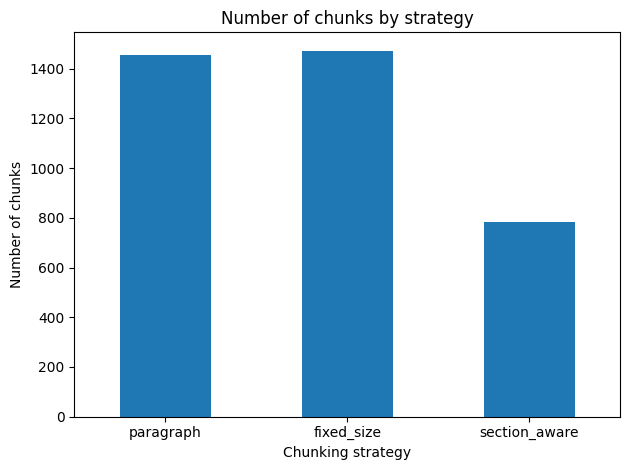

In [16]:
chunk_stats = []

for strategy, chunks in chunks_by_strategy.items():
    lengths = [
        len(chunk["text"].split())
        for chunk in chunks
    ]

    chunk_stats.append({
        "strategy": strategy,
        "num_chunks": len(chunks),
        "mean_words": np.mean(lengths) if lengths else 0,
        "median_words": np.median(lengths) if lengths else 0,
        "max_words": max(lengths, default=0),
    })

chunk_stats_df = pd.DataFrame(chunk_stats)

display(chunk_stats_df)

chunk_stats_df.plot(
    x="strategy",
    y="num_chunks",
    kind="bar",
    legend=False,
    title="Number of chunks by strategy",
    ylabel="Number of chunks",
    xlabel="Chunking strategy",
    rot=0,
)

plt.tight_layout()
plt.show()

In [17]:
model = SentenceTransformer(MODEL_NAME)

print("Loaded:", MODEL_NAME)
print("Device:", model.device)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Loaded: sentence-transformers/all-MiniLM-L6-v2
Device: cpu


In [18]:
def build_paper_indexes(chunks, model):
    grouped = defaultdict(list)

    for chunk in chunks:
        grouped[chunk["paper_id"]].append(chunk)

    indexes = {}

    for paper_id, paper_chunks in grouped.items():
        texts = [
            (
                f"Title: {chunk['title']}\n"
                f"Section: {chunk['section']}\n"
                f"Content: {chunk['text']}"
            )
            for chunk in paper_chunks
        ]

        embeddings = model.encode(
            texts,
            batch_size=32,
            convert_to_numpy=True,
            normalize_embeddings=True,
            show_progress_bar=False,
        ).astype("float32")

        index = faiss.IndexFlatIP(embeddings.shape[1])
        index.add(embeddings)

        indexes[paper_id] = {
            "index": index,
            "chunks": paper_chunks,
        }

    return indexes

In [19]:
indexes_by_strategy = {}

for strategy, chunks in chunks_by_strategy.items():
    print("Building:", strategy)

    indexes_by_strategy[strategy] = build_paper_indexes(
        chunks,
        model,
    )

print("All indexes are ready.")

Building: paragraph
Building: fixed_size
Building: section_aware
All indexes are ready.


In [20]:
def retrieve_chunks(
    question,
    paper_id,
    paper_indexes,
    top_k=TOP_K,
):
    paper_data = paper_indexes.get(paper_id)

    if paper_data is None:
        return []

    index = paper_data["index"]
    chunks = paper_data["chunks"]

    if index.ntotal == 0:
        return []

    query_embedding = model.encode(
        [question],
        convert_to_numpy=True,
        normalize_embeddings=True,
        show_progress_bar=False,
    ).astype("float32")

    scores, indices = index.search(
        query_embedding,
        min(top_k, index.ntotal),
    )

    results = []

    for score, idx in zip(scores[0], indices[0]):
        if idx < 0:
            continue

        results.append({
            **chunks[int(idx)],
            "score": float(score),
        })

    return results

In [21]:
def chunk_matches_evidence(chunk_text, evidence_list):
    chunk_norm = normalize_text(chunk_text)

    if len(chunk_norm) < 80:
        return False

    for evidence in evidence_list:
        evidence_norm = normalize_text(evidence)

        if not evidence_norm:
            continue

        if evidence_norm in chunk_norm:
            return True

        if len(chunk_norm) >= 80 and chunk_norm in evidence_norm:
            return True

    return False

In [22]:
def evaluate_strategy(strategy, paper_indexes):
    rows = []

    for q in evaluation_questions:
        paper_data = paper_indexes.get(q["paper_id"])

        if paper_data is None:
            continue

        all_chunks = paper_data["chunks"]

        # Identify relevant chunks throughout this paper's corpus.
        relevant_all = [
            chunk_matches_evidence(chunk["text"], q["evidence"])
            for chunk in all_chunks
        ]

        total_relevant = sum(relevant_all)

        if total_relevant == 0:
            rows.append({
                "strategy": strategy,
                "paper_id": q["paper_id"],
                "question_id": q["question_id"],
                "evaluated": False,
                "recall_at_k": np.nan,
                "mrr": np.nan,
                "precision_at_k": np.nan,
            })
            continue

        retrieved = retrieve_chunks(
            q["question"],
            q["paper_id"],
            paper_indexes,
            TOP_K,
        )

        relevance = [
            chunk_matches_evidence(
                item["text"],
                q["evidence"],
            )
            for item in retrieved
        ]

        relevant_ranks = [
            rank
            for rank, relevant in enumerate(relevance, start=1)
            if relevant
        ]

        recall = sum(relevance) / total_relevant

        mrr = (
            1.0 / relevant_ranks[0]
            if relevant_ranks else 0.0
        )

        precision = sum(relevance) / TOP_K

        rows.append({
            "strategy": strategy,
            "paper_id": q["paper_id"],
            "question_id": q["question_id"],
            "evaluated": True,
            "recall_at_k": recall,
            "mrr": mrr,
            "precision_at_k": precision,
        })

    return pd.DataFrame(rows)

In [23]:
result_frames = []

for strategy, indexes in indexes_by_strategy.items():
    print("Evaluating:", strategy)

    result_frames.append(
        evaluate_strategy(strategy, indexes)
    )

results_df = pd.concat(
    result_frames,
    ignore_index=True,
)

print("Evaluation finished.")
display(results_df.head())

Evaluating: paragraph
Evaluating: fixed_size
Evaluating: section_aware
Evaluation finished.


,strategy,paper_id,question_id,evaluated,recall_at_k,mrr,precision_at_k
0,paragraph,1912.01214,b6f15fb6279b82e34a5bf4828b7b5ddabfdf1d54,True,0.00,0.00,0.0
1,paragraph,1912.01214,f5e6f43454332e0521a778db0b769481e23e7682,True,0.25,1.00,0.2
2,paragraph,1912.01214,9a05a5f4351db75da371f7ac12eb0b03607c4b87,True,1.00,0.25,0.2
3,paragraph,1912.01214,5eda469a8a77f028d0c5f1acd296111085614537,True,0.50,1.00,0.2
4,paragraph,1810.08699,18c5d366b1da8447b5404eab71f4cc658ba12e6f,True,0.50,1.00,0.4


In [25]:
summary_df = (
    results_df[results_df["evaluated"]]
    .groupby("strategy")
    .agg(
        evaluated_questions=("question_id", "count"),
        recall_at_k=("recall_at_k", "mean"),
        mrr=("mrr", "mean"),
        precision_at_k=("precision_at_k", "mean"),
    )
    .reset_index()
    .sort_values("recall_at_k", ascending=False)
)

display(summary_df.round(4))

,strategy,evaluated_questions,recall_at_k,mrr,precision_at_k
2,section_aware,81,0.4780,0.3733,0.1778
1,paragraph,82,0.4055,0.3717,0.1634
0,fixed_size,82,0.3748,0.3648,0.1610


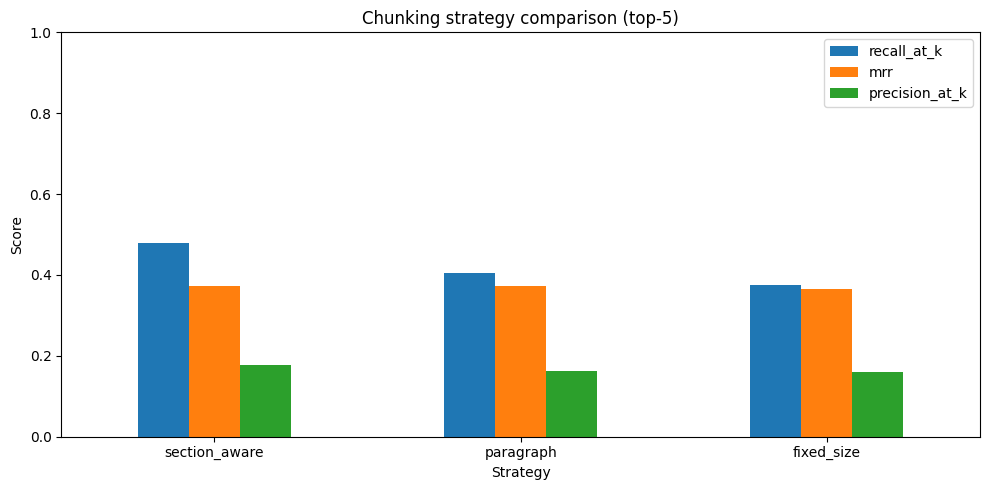

In [26]:
metrics = [
    "recall_at_k",
    "mrr",
    "precision_at_k",
]

summary_df.set_index("strategy")[metrics].plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1),
    title=f"Chunking strategy comparison (top-{TOP_K})",
)

plt.ylabel("Score")
plt.xlabel("Strategy")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [27]:
example = evaluation_questions[0]

print("Paper:", example["title"])
print("Question:", example["question"])

print("\nAnnotated evidence:")
for evidence in example["evidence"]:
    print("-", evidence[:400])

Paper: Cross-lingual Pre-training Based Transfer for Zero-shot Neural Machine Translation
Question: which multilingual approaches do they compare with?

Annotated evidence:
- Table TABREF19 and TABREF26 report zero-shot results on Europarl and Multi-UN evaluation sets, respectively. We compare our approaches with related approaches of pivoting, multilingual NMT (MNMT) BIBREF19, and cross-lingual transfer without pretraining BIBREF16. The results show that our approaches consistently outperform other approaches across languages and datasets, especially surpass pivoting,


In [28]:
for strategy, indexes in indexes_by_strategy.items():
    print("\n" + "=" * 80)
    print("STRATEGY:", strategy)

    retrieved = retrieve_chunks(
        example["question"],
        example["paper_id"],
        indexes,
        TOP_K,
    )

    for rank, chunk in enumerate(retrieved, start=1):
        relevant = chunk_matches_evidence(
            chunk["text"],
            example["evidence"],
        )

        print(
            f"\nRank {rank} | "
            f"Similarity: {chunk['score']:.3f} | "
            f"Evidence match: {relevant}"
        )
        print("Section:", chunk["section"])
        print(chunk["text"][:600])


STRATEGY: paragraph

Rank 1 | Similarity: 0.387 | Evidence match: False
Section: Experiments ::: Setup ::: Datasets.
The statistics of Europarl and MultiUN corpora are summarized in Table TABREF18. For Europarl corpus, we evaluate on French-English-Spanish (Fr-En-Es), German-English-French (De-En-Fr) and Romanian-English-German (Ro-En-De), where English acts as the pivot language, its left side is the source language, and its right side is the target language. We remove the multi-parallel sentences between different training corpora to ensure zero-shot settings. We use the devtest2006 as the validation set and the test2006 as the test set for Fr$\rightarrow $Es and De$\rightarrow $Fr. For distant language pa

Rank 2 | Similarity: 0.368 | Evidence match: False
Section: Introduction
Although Neural Machine Translation (NMT) has dominated recent research on translation tasks BIBREF0, BIBREF1, BIBREF2, NMT heavily relies on large-scale parallel data, resulting in poor performance on low-r

In [29]:
summary_df.to_csv("chunking_summary.csv", index=False)
results_df.to_csv("chunking_question_results.csv", index=False)
chunk_stats_df.to_csv("chunking_statistics.csv", index=False)

config = {
    "dataset": DATASET_ID,
    "split": EVAL_SPLIT,
    "max_papers": MAX_PAPERS,
    "max_questions_per_paper": MAX_QUESTIONS_PER_PAPER,
    "embedding_model": MODEL_NAME,
    "top_k": TOP_K,
    "chunk_size": CHUNK_SIZE,
    "overlap": CHUNK_OVERLAP,
    "strategies": list(chunkers.keys()),
}

with open("experiment_config.json", "w") as f:
    json.dump(config, f, indent=2)

print("Saved all experiment results.")

Saved all experiment results.


In [30]:
from google.colab import files

files.download("chunking_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>